# 17 · GeoTessera: from satellite years to embedding vectors

**Time:** 35 minutes · **Audience:** undergraduate / introductory graduate GIS and Earth science.

**By the end:** explain an embedding; decode quantized vectors; inspect coverage and distinguish data support from meaning.

[Run in JupyterLite](https://jltobias.github.io/JupyterLite-zarr-sql-views/lite/lab/index.html?path=17_tessera_embeddings.ipynb) · [Earth lab](https://jltobias.github.io/JupyterLite-zarr-sql-views/lab/) · [Sources and licenses](https://jltobias.github.io/JupyterLite-zarr-sql-views/book/credits.html)

Run cells from top to bottom with **Shift+Enter**. The first kernel start downloads Python WebAssembly packages.
The bundled exercises need no data-service account. Save a copy with **File → Save and Export Notebook As** before clearing browser storage.

![Four-stage workflow: STAC discovery, Zarr reading, SQL selection, linked views](assets/pipeline.svg)

In [1]:
from course import *
import numpy as np
import matplotlib.pyplot as plt
print('Ready: Python + NumPy + local teaching data')

Ready: Python + NumPy + local teaching data


## 1. A different kind of Earth observation layer

A temperature layer gives a physical quantity at a location. An **embedding** gives a vector of learned features.
TESSERA summarizes an annual sequence of optical and radar inputs. Its dimensions are useful together; dimension 7 is
not automatically vegetation, heat, poverty, or water quality. A downstream task needs evidence connecting vectors to a target.

![Satellite observations become annual vectors; compare patterns, then validate with independent evidence](assets/tessera-workflow.svg)

Our real samples come from the **v1.1 / dclimate** inference run, with 128 dimensions for each selected pixel-year.
The two small windows lie near Apapa in Lagos and Treichville in Abidjan. These are teaching windows, not port boundaries
or representative samples of either city. We retain 2018, 2021 and 2025. We do not mix model versions or inference variants.

**Predict:** would a vector by itself tell you the date of a flood? Explain why an annual summary cannot resolve that event.

In [2]:
from tessera import load_tessera, unit_vectors, scalar_map
d=load_tessera('lagos')  # try 'abidjan'
X=d['embedding']
print(d['city']['title'])
print('Axes: year, row, column, embedding dimension:', X.shape)
print('Years:', d['years'])
print('Snapshot:', d['provenance']['snapshot_id'])
print('Source grid:', d['city']['source_crs'], '| source pixel: 10 m')
print('Query spacing: 0.000375 degrees (about 42 m), individual source pixels; no averaging.')
print('Largest query-to-native-center offset (m):',round(d['city']['max_query_to_pixel_center_m'],3))

Lagos / Apapa vicinity
Axes: year, row, column, embedding dimension: (3, 64, 64, 128)
Years: [2018 2021 2025]
Snapshot: B6AFRJGX5XQC0A716PA0
Source grid: EPSG:32631 | source pixel: 10 m
Query spacing: 0.000375 degrees (about 42 m), individual source pixels; no averaging.
Largest query-to-native-center offset (m): 7.047


## 2. Decode the compact representation

The extract preserves the provider's signed 8-bit integers `q` and one positive scale `s` per pixel.
Decode using `x = q * s`. This recovers the published quantized representation, with its quantization error;
it does not reconstruct the original satellite images. Missing scales and zero-length vectors remain missing.

This library runs on native Python during preparation. JupyterLite needs only NumPy to analyze the verified extracts,
so the classroom does not depend on a live cloud request or a native Icechunk/GDAL installation.

Integer dtype: int8 | scale: 0.044783466
First eight decoded components: [ 0.6718 -0.8061 -0.627   1.2092  3.0005  0.0448 -0.7613 -0.8509]


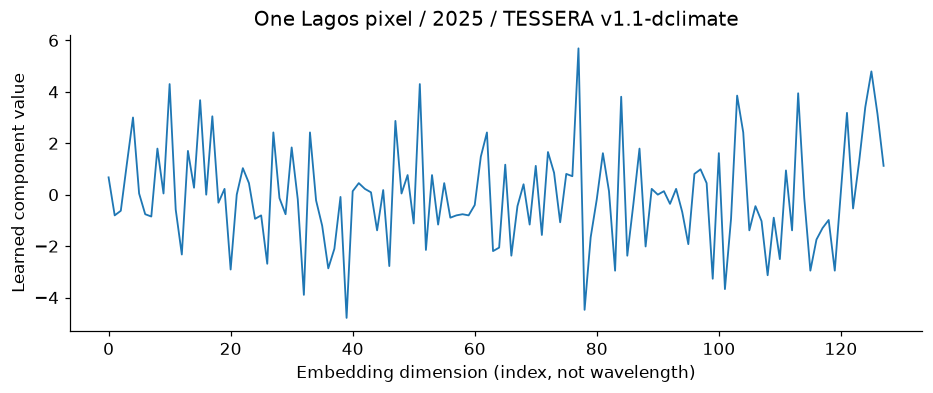

In [3]:
t,r,c=2,32,32
q=d['quantized'][t,r,c]; s=d['scales'][t,r,c]
decoded=q.astype(np.float32)*s
np.testing.assert_allclose(decoded,X[t,r,c])
print('Integer dtype:',q.dtype,'| scale:',s)
print('First eight decoded components:',np.round(decoded[:8],4))
fig,ax=plt.subplots(figsize=(10,3.5))
ax.plot(np.arange(128),decoded,lw=1.2)
ax.set(xlabel='Embedding dimension (index, not wavelength)',ylabel='Learned component value',
       title='One Lagos pixel / 2025 / TESSERA v1.1-dclimate')
plt.show()

## 3. Ask what the model was able to see

Inspect missing vectors and the number of usable optical and radar observations. These counts describe input support;
they are not confidence intervals. A valid vector may exist with no radar observations. Missing pixels are not a water mask.
All figures in this studio show values sampled from individual 10 m native pixels at a coarser geographic query grid.
The displayed squares do not mean every point in that square was measured.

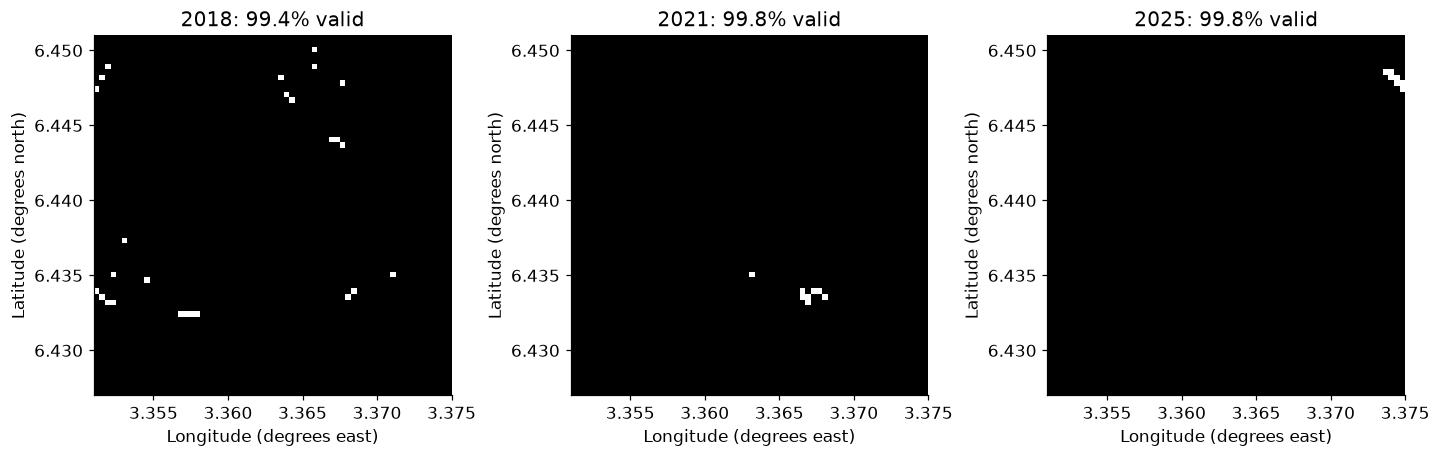

2018 valid pixels: 4070 median optical count: 25.0 valid pixels with zero radar: 0
2021 valid pixels: 4088 median optical count: 25.0 valid pixels with zero radar: 0
2025 valid pixels: 4089 median optical count: 24.0 valid pixels with zero radar: 0


In [4]:
fig,axes=plt.subplots(1,3,figsize=(13,4),layout='constrained')
for ax,year,valid in zip(axes,d['years'],d['valid']):
    scalar_map(ax,d,valid.astype(float),f'{year}: {valid.mean():.1%} valid',cmap='gray_r',vmin=0,vmax=1)
plt.show()
for i,year in enumerate(d['years']):
    valid=d['valid'][i]
    radar=d['s1_asc_obs_count'][i]+d['s1_desc_obs_count'][i]
    print(year,'valid pixels:',valid.sum(),
          'median optical count:',float(np.median(d['s2_obs_count'][i][valid])),
          'valid pixels with zero radar:',int((valid&(radar==0)).sum()))

## 4. Inspect the evidence trail

The public source is a Zarr store in an Icechunk repository. An Icechunk snapshot identifies a consistent state of that store.
The checksums identify the exact local extracts. These solve different reproducibility problems.

The optional native preparation command, run from a checkout outside JupyterLite, is:

```bash
python -m pip install -r requirements-tessera.txt
python scripts/prepare_tessera.py --fetch
```

It reads six bounded spatial windows and reuses verified extracts. The checked-in provenance pins the snapshot.
Cloud chunk sizes make network transfer larger than the final samples; do not extrapolate output size to download cost.

In [5]:
for item in d['provenance']['artifacts']:
    print(item['file'], f"{item['bytes']/1e6:.2f} MB", item['sha256'][:16]+'...')
raw_bytes=d['quantized'].nbytes+d['scales'].nbytes
print('This city, q + scales:',raw_bytes,'bytes; decoded float32:',X.nbytes,'bytes')

tessera_lagos_2018.npz 0.55 MB d7baec742ac15f6f...
tessera_lagos_2021.npz 0.56 MB eb76bb85994852ef...
tessera_lagos_2025.npz 0.56 MB dec230293bf50ccf...
tessera_abidjan_2018.npz 0.55 MB 847f3f73ac5760f9...
tessera_abidjan_2021.npz 0.55 MB c1f34b6533622f48...
tessera_abidjan_2025.npz 0.56 MB 589b177ca335213e...
This city, q + scales: 1622016 bytes; decoded float32: 6291456 bytes


## Try it yourself

Switch to Abidjan. Compare valid coverage and observation counts, then explain why different counts alone do not prove different model accuracy.

## Check your reasoning

An embedding is a learned description, not a measured hazard. A missing vector, a low observation count, and an inaccurate prediction are three different things.

## Evidence journal

Write four sentences: **what I observed; how I calculated it; what this cannot establish; what evidence I need next**.
For any figure you reuse, retain its units, date or scenario, data origin, transformations, and attribution.

## Sources and credit

- [TESSERA project](https://geotessera.org/) and [model repository](https://github.com/ucam-eo/tessera), University of Cambridge and collaborators.
- [Feng et al., TESSERA: Temporal Embeddings of Surface Spectra for Earth Representation and Analysis](https://doi.org/10.48550/arXiv.2506.20380), 2025, revised 2026.
- [GeoTessera Python client](https://github.com/ucam-eo/geotessera), MIT; pinned preparation commit in the provenance.
- [dClimate global-store documentation](https://github.com/dClimate/tessera-embeddings/blob/main/docs/global-store.md): annual v1.1-dclimate embeddings and observation counts.
- [Bundled source snapshot, coordinates, transformations and checksums](https://jltobias.github.io/JupyterLite-zarr-sql-views/data/tessera-provenance.json). Embedding data: CC0-1.0; [upstream terms and advisory guidelines](https://github.com/ucam-eo/tessera/blob/master/aup.md).

Teaching adaptation of [dzole0311/zarr-sql-views](https://github.com/dzole0311/zarr-sql-views), ISC.
Original teaching code and prose: JupyterLite-zarr-sql-views contributors, ISC. Data keep their separate licenses.

In [6]:
print('LESSON COMPLETE: 17_tessera_embeddings')

LESSON COMPLETE: 17_tessera_embeddings
